# 04 - Sioux Falls network (Appendix C)

Sioux Falls network (24 nodes, 38 edges) with random DoS. Comparison of the algorithms (Fig. 11, Appendix C) and computation times (Table VIII). Runtime: about 1-2 hours for everything (Bayesian is the slowest).

**Choose the model variant** (see README, section *Two model variants*):

* `"dos"` (default) - integer DoS weights, linear models in $s_\mathcal{G}$ and $l_\mathcal{G}$ (ITSC-2024 calibration), exponential cost per metre.
* `"cscs"` - CycleRAP/CSCS weights, NNLS model $\tilde\theta=[0.41, 0.58, 0.45, 0.57]$ of Eq. (10), Cerema costs.
  With this model safety and comfort percentages are identical, because the prediction only depends on $l_\mathcal{G}$.

The GA and the Bayesian optimiser are stochastic: their results vary from run to run (seed fixed below for repeatability). MLCC and the brute-force optimum are deterministic.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # the cycling_tits package

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from cycling_tits import CITIES, FIGURES, RESULTS, load_network, load_survey, pretty, Model, alphas
FIGURES.mkdir(exist_ok=True)

In [2]:
from cycling_tits.experiments import compare_algorithms, percents, ga_histories, time_table
from cycling_tits.plotting import comparison_bars, ga_evolution

PRESET = "dos"                # or "cscs"
TARGETS = ["safety", "comfort"]
METHODS = ['MLCC', 'SGA', 'SGA-MLCC', 'Bayesian']
QUICK = False                  # True: very short GA / Bayesian runs, only to test the notebook
GENERATIONS, POP_SIZE, BAYES_CALLS = (5, 10, 10) if QUICK else (80, 50, 20)
SEED = 0
TAG = "_quick" if QUICK else ""
OUT = FIGURES / PRESET; OUT.mkdir(exist_ok=True)

In [3]:
results = {t: compare_algorithms("Sioux_Falls", PRESET, t, METHODS, generations=GENERATIONS, pop_size=POP_SIZE,
                                bayes_calls=BAYES_CALLS, seed=SEED, tag=TAG)
           for t in TARGETS}

loaded cached results results\dos\Sioux_Falls_safety.json
loaded cached results results\dos\Sioux_Falls_comfort.json


## % of achievable improvement  $100\,|\hat y_{\omega_0}-\hat y(\omega^*)| / |\hat y_{FS}-\hat y_{\omega_0}|$

In [4]:
tables = {t: pd.DataFrame({m: percents(results[t], m) for m in METHODS}, index=[f"i={i}" for i in range(10)]).T.round(2)
          for t in TARGETS}
tables["safety"]

,i=0,i=1,i=2,i=3,i=4,i=5,i=6,i=7,i=8,i=9
MLCC,0.85,1.01,1.81,5.22,13.56,19.02,25.84,42.77,68.94,100.00
SGA,2.03,3.98,5.01,7.45,11.94,20.17,32.57,55.81,80.09,100.00
SGA-MLCC,2.48,3.35,5.06,8.23,13.82,21.70,38.88,58.42,78.49,100.00
Bayesian,1.34,2.23,3.24,4.24,7.06,14.98,20.75,33.13,34.44,34.44


In [5]:
tables["comfort"]

,i=0,i=1,i=2,i=3,i=4,i=5,i=6,i=7,i=8,i=9
MLCC,0.67,0.76,1.69,5.01,13.55,19.11,25.71,42.93,69.45,100.00
SGA,2.35,3.65,4.82,8.83,10.87,18.47,32.24,59.11,78.52,100.00
SGA-MLCC,2.32,3.15,4.81,8.25,13.62,21.26,39.37,53.53,85.43,100.00
Bayesian,1.16,2.00,2.86,3.62,6.34,14.34,19.88,32.33,33.42,33.42


## Fig. 11 (a) - comparison of the algorithms (plain = safety, hatched = comfort)

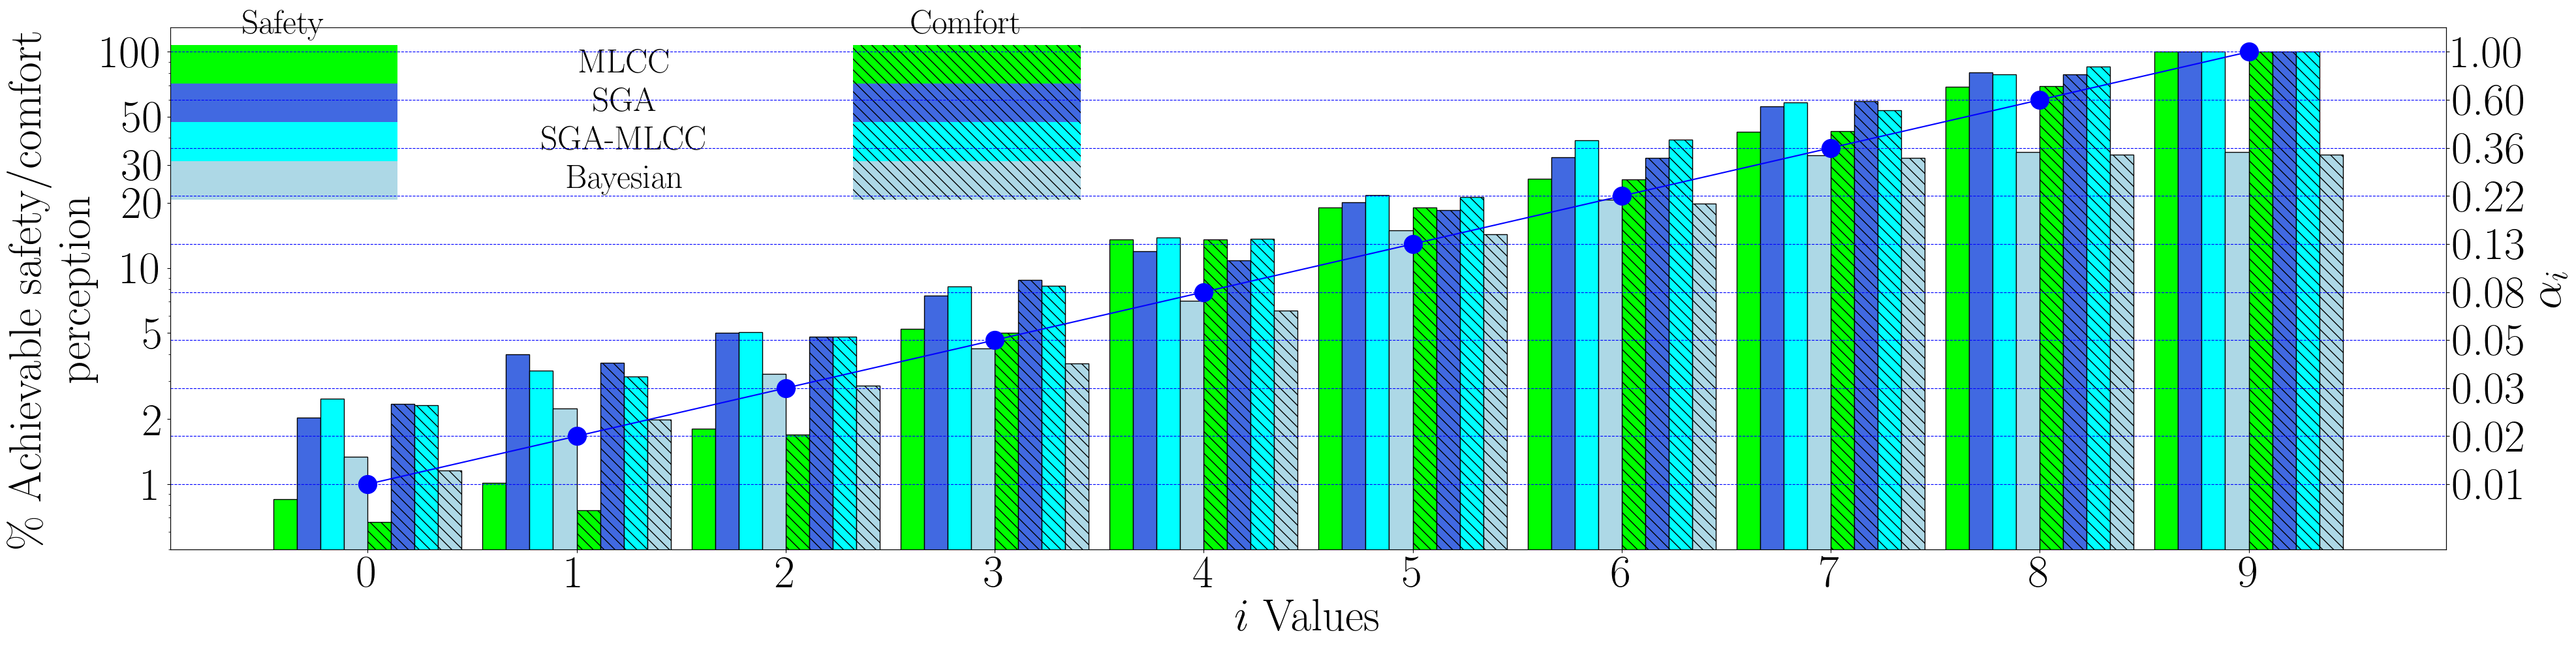

In [6]:
comparison_bars({m: percents(results["safety"], m) for m in METHODS},
                {m: percents(results["comfort"], m) for m in METHODS},
                outfile=OUT / "maximize_safety_academic_example_Sioux_Falls.png", methods=METHODS);

## Fig. 11 (b), (c) - evolution of SGA and SGA-MLCC over the generations (safety)

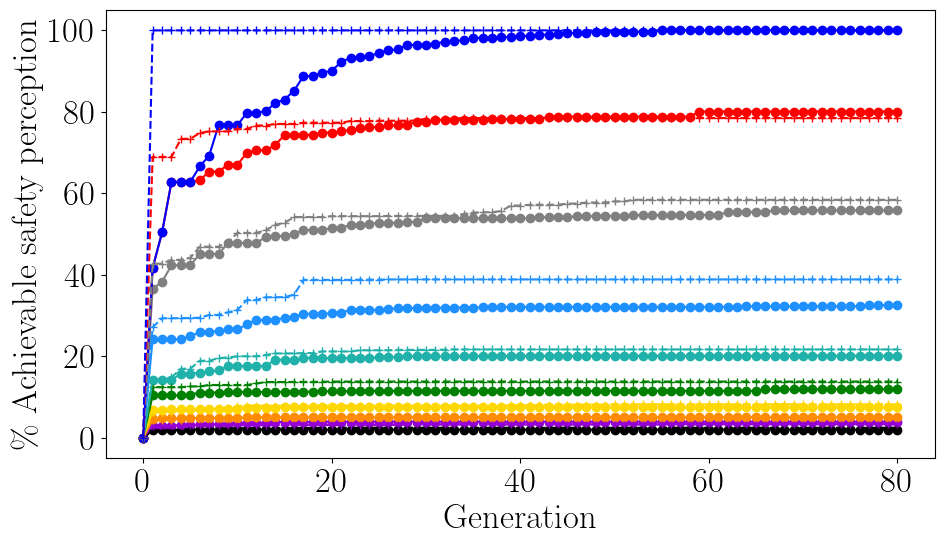

In [7]:
ga_evolution(ga_histories(results["safety"], "SGA"), ga_histories(results["safety"], "SGA-MLCC"),
             outfile=OUT / "Sioux_Falls_comparation_GA_LCC_safety.png",
             legend_outfile=OUT / "Sioux_Falls_comparation_GA_LCC_safety_legend.png");

## Table VIII - computation time

In [8]:
time_table(results["safety"], METHODS)

,i = 0,i = 1,i = 2,i = 3,i = 4,i = 5,i = 6,i = 7,i = 8,i = 9
MLCC,0.0181 s,0.0151 s,0.0169 s,0.0217 s,0.0208 s,0.0215 s,0.0206 s,0.0239 s,0.0275 s,0.0369 s
SGA,15.04 s,14.69 s,14.91 s,17.87 s,18.32 s,19.99 s,24.16 s,26.33 s,28.87 s,28.75 s
SGA-MLCC,15.31 s,15.08 s,15.74 s,16.62 s,17.78 s,19.99 s,20.82 s,24.04 s,26.73 s,15.14 s
Bayesian,11.95 s,12.28 s,11.32 s,11.06 s,11.55 s,10.72 s,11.76 s,11.56 s,10.68 s,11.80 s
